In [1]:
import pandas as  pd
## charger dataset
df= pd.read_csv("Titanic.csv")
print(df.shape)


(891, 10)


In [2]:
## identifier le type des données 
print(df.dtypes)


sex          object
age         float64
sibsp         int64
parch         int64
fare        float64
embarked     object
class        object
who          object
alone          bool
survived      int64
dtype: object


In [3]:
## visualiser les premiers lignes
print(df.head())


      sex   age  sibsp  parch     fare embarked  class    who  alone  survived
0    male  22.0      1      0   7.2500        S  Third    man  False         0
1  female  38.0      1      0  71.2833        C  First  woman  False         1
2  female  26.0      0      0   7.9250        S  Third  woman   True         1
3  female  35.0      1      0  53.1000        S  First  woman  False         1
4    male  35.0      0      0   8.0500        S  Third    man   True         0


In [4]:
## vérifier les valeurs manquantes
print(df.isnull().sum())


sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
class         0
who           0
alone         0
survived      0
dtype: int64


In [5]:
##  Identifier les colonnes avec des valeurs manquantes 
print(df.isna().mean()) 

sex         0.000000
age         0.198653
sibsp       0.000000
parch       0.000000
fare        0.000000
embarked    0.002245
class       0.000000
who         0.000000
alone       0.000000
survived    0.000000
dtype: float64


In [6]:
print("le nombre des colonnes avant les supprission des variables ayant plus 40% des vleurs manquants:", df.shape[1])
moy = (df.isnull().sum() / len(df)) * 100
cols_to_drop = []
for col in df.columns:
    if moy[col] > 40:
        cols_to_drop.append(col)

if cols_to_drop:
    df = df.drop(columns=cols_to_drop)
print("le résultats apres la gestion", df.shape[1])

le nombre des colonnes avant les supprission des variables ayant plus 40% des vleurs manquants: 10
le résultats apres la gestion 10


In [7]:
from sklearn.impute import SimpleImputer

## pour les variables numériques on remplace les valeurs manquants par le "median":
col_num = df.select_dtypes(include=['number']).columns
num_imputer = SimpleImputer(strategy="median")
df[col_num] = num_imputer.fit_transform(df[col_num])
## vérifies la modification des valeurs manquants
print(df.isna().sum())

sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    2
class       0
who         0
alone       0
survived    0
dtype: int64


In [8]:
## por les variables catégorielles on remplace les valeur manquants par le "mode":
cols_cat = df.select_dtypes(include=['object']).columns
cat_imputer = SimpleImputer(strategy="most_frequent")

df[cols_cat] = cat_imputer.fit_transform(df[cols_cat])
## vérifies la modification des valeurs manquants
print(df.isna().sum())

sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
class       0
who         0
alone       0
survived    0
dtype: int64


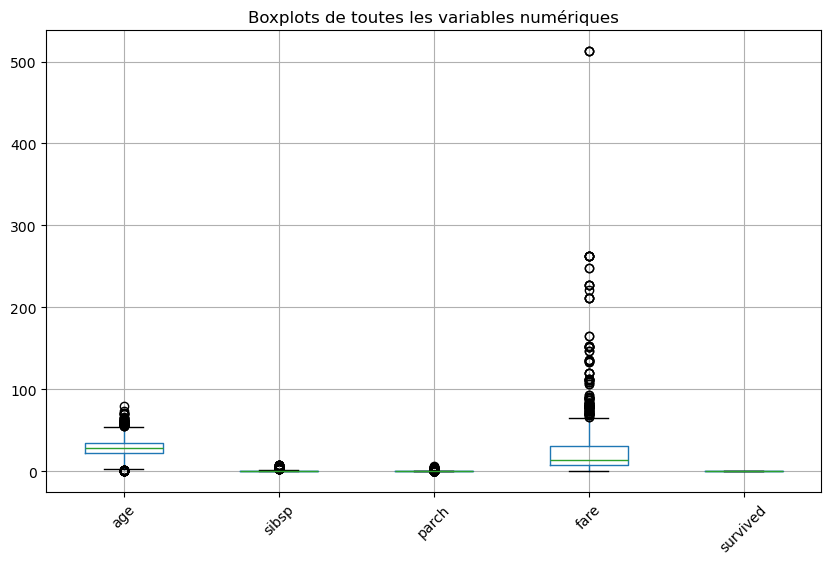

In [12]:
## detecter les valeurs aberrantes en utilise boxplot:
import seaborn as sns
import matplotlib.pyplot as plt
df.select_dtypes(include=['number']).boxplot(figsize=(10, 6))
plt.title('Boxplots de toutes les variables numériques')
plt.xticks(rotation=45)
plt.show()

 Q1 :7.9104  ________  Q3: 31.0
IQR  :  23.0896
borne inférieur   :  -26.724
borne supérieurs  :  65.6344


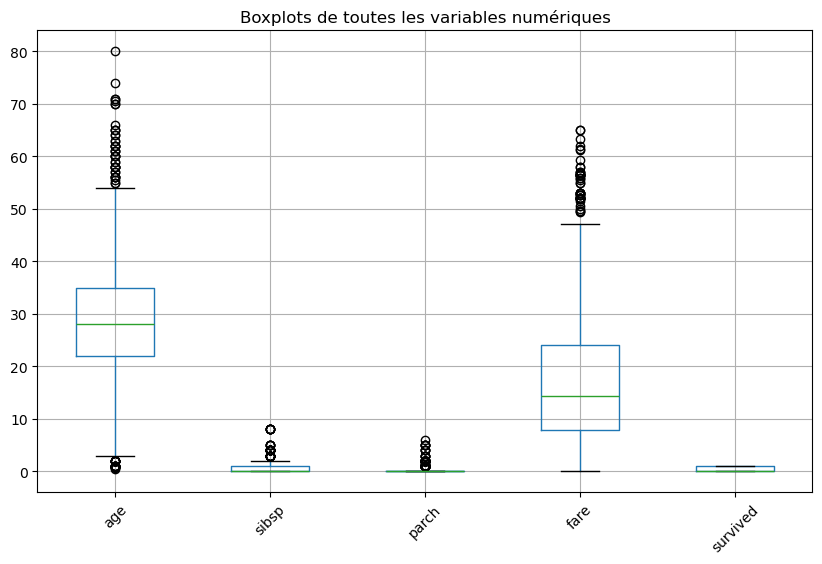

In [35]:
## d'aprés les histogramme le colone traiter est colonne "fare"
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
print(f" Q1 :{Q1:3}  ________  Q3: {Q3:3}")
IQR = Q3-Q1
print(f"IQR  :  {IQR:3}")
##définir les seuils infirieur et supérieur
bor_inf = Q1 - (1.5*IQR)
bor_sup = Q3 + (1.5*IQR)
## afficher les bornes :
print(f"borne inférieur   :  {bor_inf:3}")
print(f"borne supérieurs  :  {bor_sup:3}")
## remplace les valeurs aberrantes par la médian
df.loc[(df['fare'] < bor_inf )|(df['fare'] > bor_sup ) , 'fare' ]=df['fare'].median()
## vérifier les modéfications: 
df.select_dtypes(include=['number']).boxplot(figsize=(10, 6))
plt.title('Boxplots de toutes les variables numériques')
plt.xticks(rotation=45)
plt.show()

In [36]:
## identifier les colonnes avec des valeurs catégorielles :
col_cat = df.select_dtypes(include=['object']).columns
print("les colonnes catégorielles sont: :", list(col_cat))

les colonnes catégorielles sont: : ['sex', 'embarked', 'class', 'who']


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, MinMaxScaler, StandardScaler
## selectionner les colonnes nominales :
col_nominal = ['sex', 'embarked', 'who', 'alone'] 
##  applique le codage onehot sur les variables nominales:
nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')), 
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

## selectionnes les colonnes ordinales :
col_ordinal = ['class']
##applique le codage ordinale sur les variables ordinales:
ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=[[ 'First', 'Second', 'Third']]))
])

In [10]:
## selectionnes les colonnes numériques :
col_num = df.select_dtypes(include=['number']).columns
## applique la normalisation sur les variables numériques:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])
preprocessor = ColumnTransformer(
    transformers=[
        ('nom', nominal_pipeline, col_nominal),
        ('ord', ordinal_pipeline, col_ordinal),
        ('num', numeric_pipeline, col_num)
    ]
)
X_processed = preprocessor.fit_transform(df)
df_processed = pd.DataFrame(X_processed, columns=preprocessor.get_feature_names_out())
print(df_processed.head(10))

   nom__sex_female  nom__sex_male  nom__embarked_C  nom__embarked_Q  \
0              0.0            1.0              0.0              0.0   
1              1.0            0.0              1.0              0.0   
2              1.0            0.0              0.0              0.0   
3              1.0            0.0              0.0              0.0   
4              0.0            1.0              0.0              0.0   
5              0.0            1.0              0.0              1.0   
6              0.0            1.0              0.0              0.0   
7              0.0            1.0              0.0              0.0   
8              1.0            0.0              0.0              0.0   
9              1.0            0.0              1.0              0.0   

   nom__embarked_S  nom__who_child  nom__who_man  nom__who_woman  \
0              1.0             0.0           1.0             0.0   
1              0.0             0.0           0.0             1.0   
2             

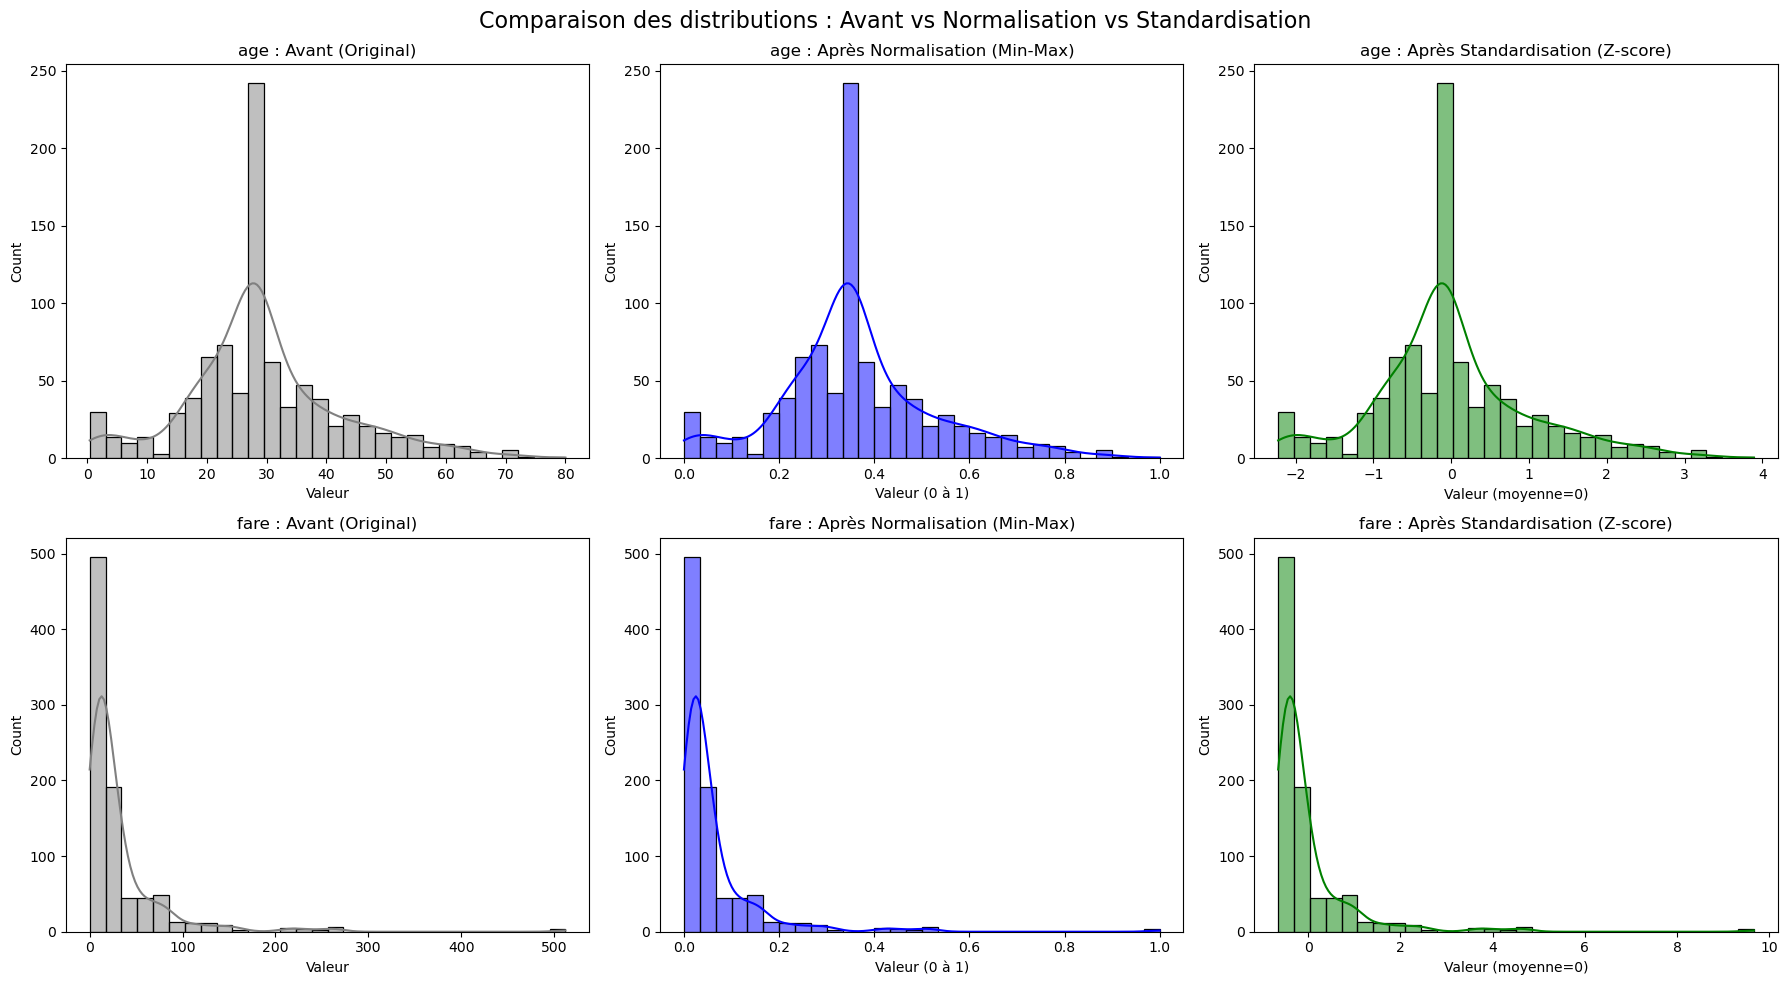

In [13]:
## selection seulement 2 colonnes pour la verification:
num_cols = ['age', 'fare']
## les donnes avant le traitement :
df_raw = df[num_cols].copy()
df_raw['age'] = df_raw['age'].fillna(df_raw['age'].median())
df_raw['fare'] = df_raw['fare'].fillna(df_raw['fare'].median())
df_raw = df_raw.reset_index(drop=True)
## la normalisation: 
pipe_minmax = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])
X_minmax = pipe_minmax.fit_transform(df[num_cols])
df_minmax = pd.DataFrame(X_minmax, columns=num_cols)

## standarisation :
pipe_standard = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
X_standard = pipe_standard.fit_transform(df[num_cols])
df_standard = pd.DataFrame(X_standard, columns=num_cols)
## histogramme :

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
fig.suptitle('Comparaison des distributions : Avant vs Normalisation vs Standardisation', fontsize=16)

for i, col in enumerate(num_cols):
    
    sns.histplot(df_raw[col], bins=30, kde=True, ax=axes[i, 0], color='gray')
    axes[i, 0].set_title(f"{col} : Avant (Original)")
    axes[i, 0].set_xlabel("Valeur")

    # ب. بعد Normalisation (Min-Max)
    sns.histplot(df_minmax[col], bins=30, kde=True, ax=axes[i, 1], color='blue')
    axes[i, 1].set_title(f"{col} : Après Normalisation (Min-Max)")
    axes[i, 1].set_xlabel("Valeur (0 à 1)")

    # ج. بعد Standardisation (Z-score)
    sns.histplot(df_standard[col], bins=30, kde=True, ax=axes[i, 2], color='green')
    axes[i, 2].set_title(f"{col} : Après Standardisation (Z-score)")
    axes[i, 2].set_xlabel("Valeur (moyenne=0)")

plt.tight_layout()
plt.show()

In [14]:
## identifiez le déséquilibre :
print("Effectifs par classe:")
print(df['survived'].value_counts())

Effectifs par classe:
survived
0.0    549
1.0    342
Name: count, dtype: int64


In [44]:
## séparé les données :
from imblearn.under_sampling import RandomUnderSampler
print("la distribution avant undersampling  :")
print( df['survived'].value_counts())
X = df.drop('survived', axis=1)
y = df['survived']
rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X, y)
print("la distribution aprés undersampling:")
print(y_under.value_counts())

la distribution avant undersampling  :
survived
0.0    549
1.0    342
Name: count, dtype: int64
la distribution aprés undersampling:
survived
0.0    342
1.0    342
Name: count, dtype: int64


In [45]:
from imblearn.over_sampling import SMOTE

X_processed = preprocessor.fit_transform(X)
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_processed, y)
print("la distribution apres Oversampling (SMOTE):")
print(y_over.value_counts())


ValueError: A given column is not a column of the dataframe